# Model selection

Which of several candidate model structures does the data support? Adding reactions or regulations always improves the fit, so a more complex model has to improve it by enough to justify its extra parameters.
`mxlpy.select` fits each candidate from several starting points and compares them with **information criteria** or **likelihood-ratio tests**:

- AIC $= 2k - 2\,\mathrm{LL}$, AICc $= \mathrm{AIC} + \frac{2k(k+1)}{n-k-1}$ (small-sample correction), BIC $= k \ln n - 2\,\mathrm{LL}$

with $k$ estimated parameters, $n$ data points and the maximised log-likelihood $\mathrm{LL}$. This needs a likelihood loss, `fit.GaussianNll(sigma)` for Gaussian measurement noise.

In [1]:
import numpy as np

from mxlpy import Model, Simulator, fit, fns, plot, select
from mxlpy.distributions import LogUniform

As an example, a two-step decay $x \to y \to \varnothing$ generates noisy data.
We pretend not to know whether $y$ is degraded and whether $x$ has a degradation of its own.

In [2]:
def decay() -> Model:
    return (
        Model()
        .add_parameters({"k1": 0.5, "k2": 2.0})
        .add_variables({"x": 2.0, "y": 0.0})
        .add_reaction(
            "v1", fns.mass_action_1s, args=["x", "k1"], stoichiometry={"x": -1, "y": 1}
        )
        .add_reaction(
            "v2", fns.mass_action_1s, args=["y", "k2"], stoichiometry={"y": -1}
        )
    )


sigma = 0.01
t = np.linspace(0.2, 6.0, 20)
res = Simulator(decay()).simulate_time_course(t).get_result().unwrap_or_err()
data = res.get_combined().loc[t, ["x", "y"]]
data += np.random.default_rng(0).normal(0, sigma, data.shape)

## Model space

A `ModelSpace` is a base model and named **switches**. Each combination of switches that are on is a candidate.

- `select.free_parameter(name, fixed_value)` estimates a parameter when on and fixes it when off. Fixing it at the value where the feature vanishes (here a rate of 0) makes the models *nested*.
- A plain function changes the model when the switch is on, e.g. adding a reaction.
- `select.Switch(on=..., off=..., fix_on=..., fix_off=...)` covers the general case, and `allowed=` excludes combinations.

In [3]:
def add_x_degradation(m: Model) -> None:
    m.add_parameter("kx", 0.1)
    m.add_reaction("vx", fns.mass_action_1s, args=["x", "kx"], stoichiometry={"x": -1})


space = select.ModelSpace(
    base=decay(),
    switches={
        "deg_y": select.free_parameter("k2", fixed_value=0.0),
        "deg_x": add_x_degradation,
    },
)

## Structure search

`select.run` searches the space. The parameters to estimate come with the distribution random starts are drawn from; each candidate estimates those its model has and doesn't fix.

- `forward` turns one switch on at a time, `backward` one off.
- `adaptive` alternates forward, backward and swap moves until none improves the criterion.
- `brute_force` fits every candidate.

Every candidate is fitted from `n_starts` random starts plus a warm start from the optimum of the model the search came from.

In [4]:
parameters = {
    "k1": LogUniform(1e-2, 1e1),
    "k2": LogUniform(1e-2, 1e1),
    "kx": LogUniform(1e-3, 1e0),
}
selection = select.run(
    space,
    data,
    parameters,
    loss_fn=fit.GaussianNll(sigma),
    criterion="aicc",
    method="brute_force",
    n_starts=5,
    bounds={"k1": (1e-6, 1e3), "k2": (0.0, 1e3), "kx": (0.0, 1e3)},
)
selection.table

fits:   0%|          | 0/24 [00:00<?, ?it/s]

fits:   4%|▍         | 1/24 [00:03<01:20,  3.48s/it]

fits:  25%|██▌       | 6/24 [00:03<00:08,  2.21it/s]

fits:  46%|████▌     | 11/24 [00:03<00:03,  4.27it/s]

fits:  88%|████████▊ | 21/24 [00:04<00:00,  8.38it/s]

fits: 100%|██████████| 24/24 [00:04<00:00,  5.46it/s]

,k,n,log_likelihood,aic,aicc,bic,delta,weight,converged,n_failed,parent,deg_y,deg_x
model,,,,,,,,,,,,,
deg_y,2,40,-11.379443,26.758885,27.083210,30.136644,0.000000,0.759592,1.0,0,None,True,False
deg_y+deg_x,3,40,-11.358717,28.717434,29.384101,33.784073,2.300891,0.240408,1.0,0,None,True,True
deg_x,2,40,-1817.655044,3639.310088,3639.634413,3642.687847,3612.551203,0.000000,1.0,0,None,False,True
base,1,40,-99435.574729,198873.149457,198873.254720,198874.838337,198846.171510,0.000000,1.0,0,None,False,False


The table ranks the candidates by the criterion. `delta` is the difference to the best candidate and `weight` the Akaike weight, the relative support of each model among the candidates.
`converged` is the fraction of starts that reached the best fit, and `n_failed` counts failed starts.
Differences above 2 count as some, above 10 as strong evidence against a model.

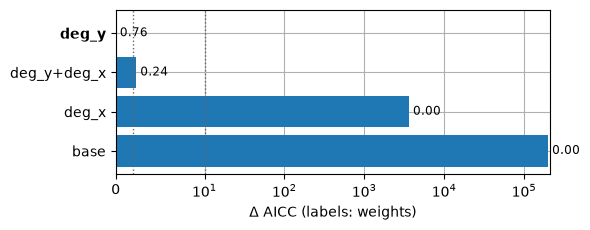

In [5]:
_ = plot.model_selection(selection)

In [6]:
selection.best_id, selection.best.best_pars

('deg_y', {'k1': 0.5028790056316224, 'k2': 1.9965448067547977})

## Likelihood-ratio tests

For nested models, a likelihood-ratio test asks if the larger model fits significantly better.
Here, the extra degradation of $x$ doesn't improve the fit significantly, while the degradation of $y$ does.

In [7]:
selection.lrt("deg_y", "deg_y+deg_x"), selection.lrt("base", "deg_y")

(LikelihoodRatio(statistic=0.0414513607499174, df=1, p_value=0.838669162529756),
 LikelihoodRatio(statistic=198848.39057155588, df=1, p_value=0.0))

`criterion="lrt"` uses these tests in the search instead of a criterion: forward moves need a significant improvement, backward moves must not make the fit significantly worse.
Here we continue from the previous selection with `reuse=`, so no candidate is fitted again.

In [8]:
lrt_selection = select.run(
    space,
    data,
    parameters,
    loss_fn=fit.GaussianNll(sigma),
    criterion="lrt",
    method="forward",
    reuse=selection,
)
lrt_selection.path

['base', 'deg_y']

## Comparing explicit variants

`select.compare` fits and ranks models given directly, e.g. alternative rate laws written by hand.
The criteria are also available as plain functions (`select.aic`, `select.aicc`, `select.bic`, `select.model_weights`, `select.lrt`).

In [9]:
variants = {
    "two-step": decay(),
    "with x degradation": space.build(["deg_y", "deg_x"])[0],
}
select.compare(
    variants, data, parameters, loss_fn=fit.GaussianNll(sigma), criterion="bic"
).table

fits:   0%|          | 0/22 [00:00<?, ?it/s]

fits:   5%|▍         | 1/22 [00:03<01:08,  3.26s/it]

fits:  18%|█▊        | 4/22 [00:03<00:11,  1.51it/s]

fits:  41%|████      | 9/22 [00:03<00:03,  4.06it/s]

fits:  64%|██████▎   | 14/22 [00:03<00:01,  7.17it/s]

fits: 100%|██████████| 22/22 [00:03<00:00,  5.92it/s]

,k,n,log_likelihood,aic,aicc,bic,delta,weight,converged,n_failed,parent
model,,,,,,,,,,,
two-step,2,40,-11.379443,26.758885,27.083210,30.136644,0.000000,0.861011,1.0,0,None
with x degradation,3,40,-11.358718,28.717437,29.384103,33.784075,3.647431,0.138989,1.0,0,None
